# Working with complexes and spectral pages

A resolution, a Hom computation or a supplied diagram can lead to a complex of vector spaces. Once its differential is known, we can ask which vectors are cycles, which are boundaries, and what a map does to their classes. These operations may follow a finite encoding; they also accept directly supplied algebraic data.

We first follow a vector through those questions, including a map that kills its class. A mapping cone then gives a concrete connecting map. Finally, a filtered example lets us inspect successive spectral pages and see why one unchanged page need not mean convergence.

You need matrix kernels and quotients, plus the packages in the [installation instructions](../src/start/install.md). The figures are static and reproducible. Linked browser inspectors are optional ways to explore the same objects.

In [1]:
using TamerOp, SparseArrays, CairoMakie
const OA = TamerOp.Advanced
const K = Rational{BigInt}
field = TamerOp.CoreModules.QQField()

TamerOp.CoreModules.CoeffFields.QQField()

## Start with the differential

Consider the cochain complex

$$K \xrightarrow{(1,0,0)^T} K^3 \xrightarrow{(0,0,1)} K.$$

The second arrow sends $(a,b,c)$ to $c$. Its kernel is the plane spanned by the first two coordinate vectors; the incoming image is the first coordinate axis. Their quotient therefore has dimension one, represented by the second coordinate vector.

The package stores degrees increasing under the differential. Each matrix uses target rows and source columns. We begin with the matrices themselves; drawing the complex does not request a quotient basis.

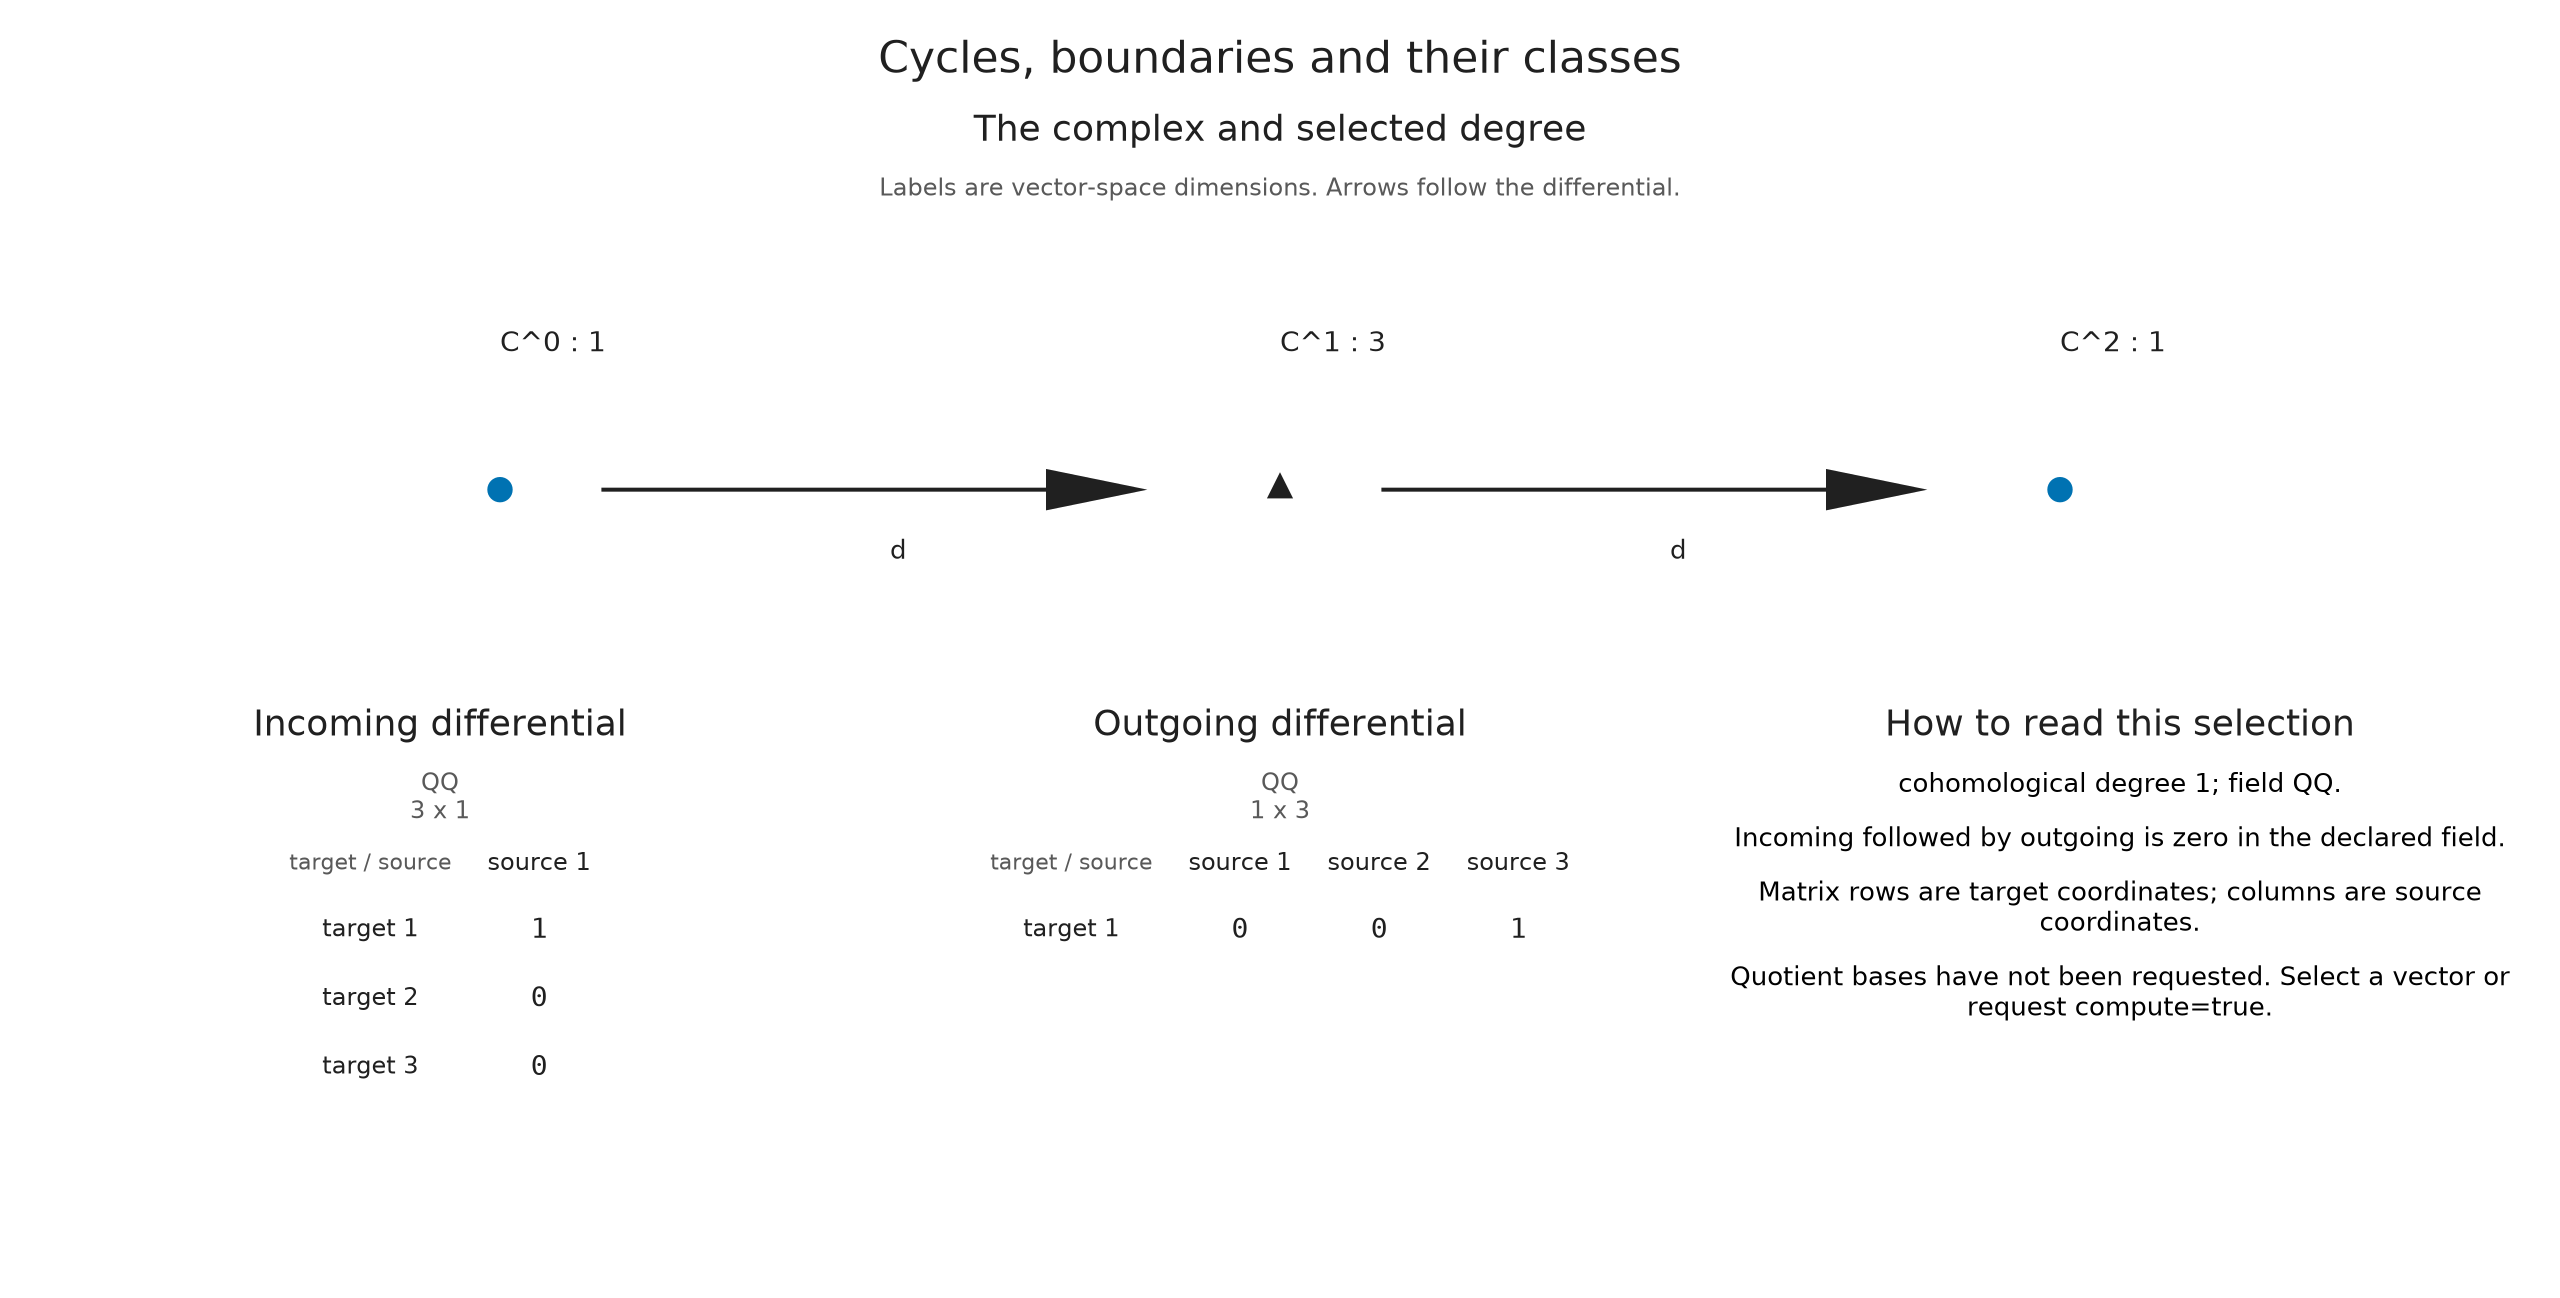

In [2]:
C = OA.CochainComplex{K}(0, 2, [1,3,1],
    [sparse(reshape(K[1,0,0],3,1)), sparse(reshape(K[0,0,1],1,3))]; field)
OA.check_complex(C; throw=true)
visualize(C; degree=1)

## Ask what a vector represents

Take $z=(1,1,0)$. Its differential is zero, so it is a cycle. Its first coordinate is already an incoming boundary; removing that coordinate leaves the same class as $(0,1,0)$.

A vector selection requests this calculation explicitly. The view distinguishes the original vector, its quotient coordinates and a chosen representative. The boundary adjustment $w$ verifies $z=r+d(w)$, where $r$ is that representative.

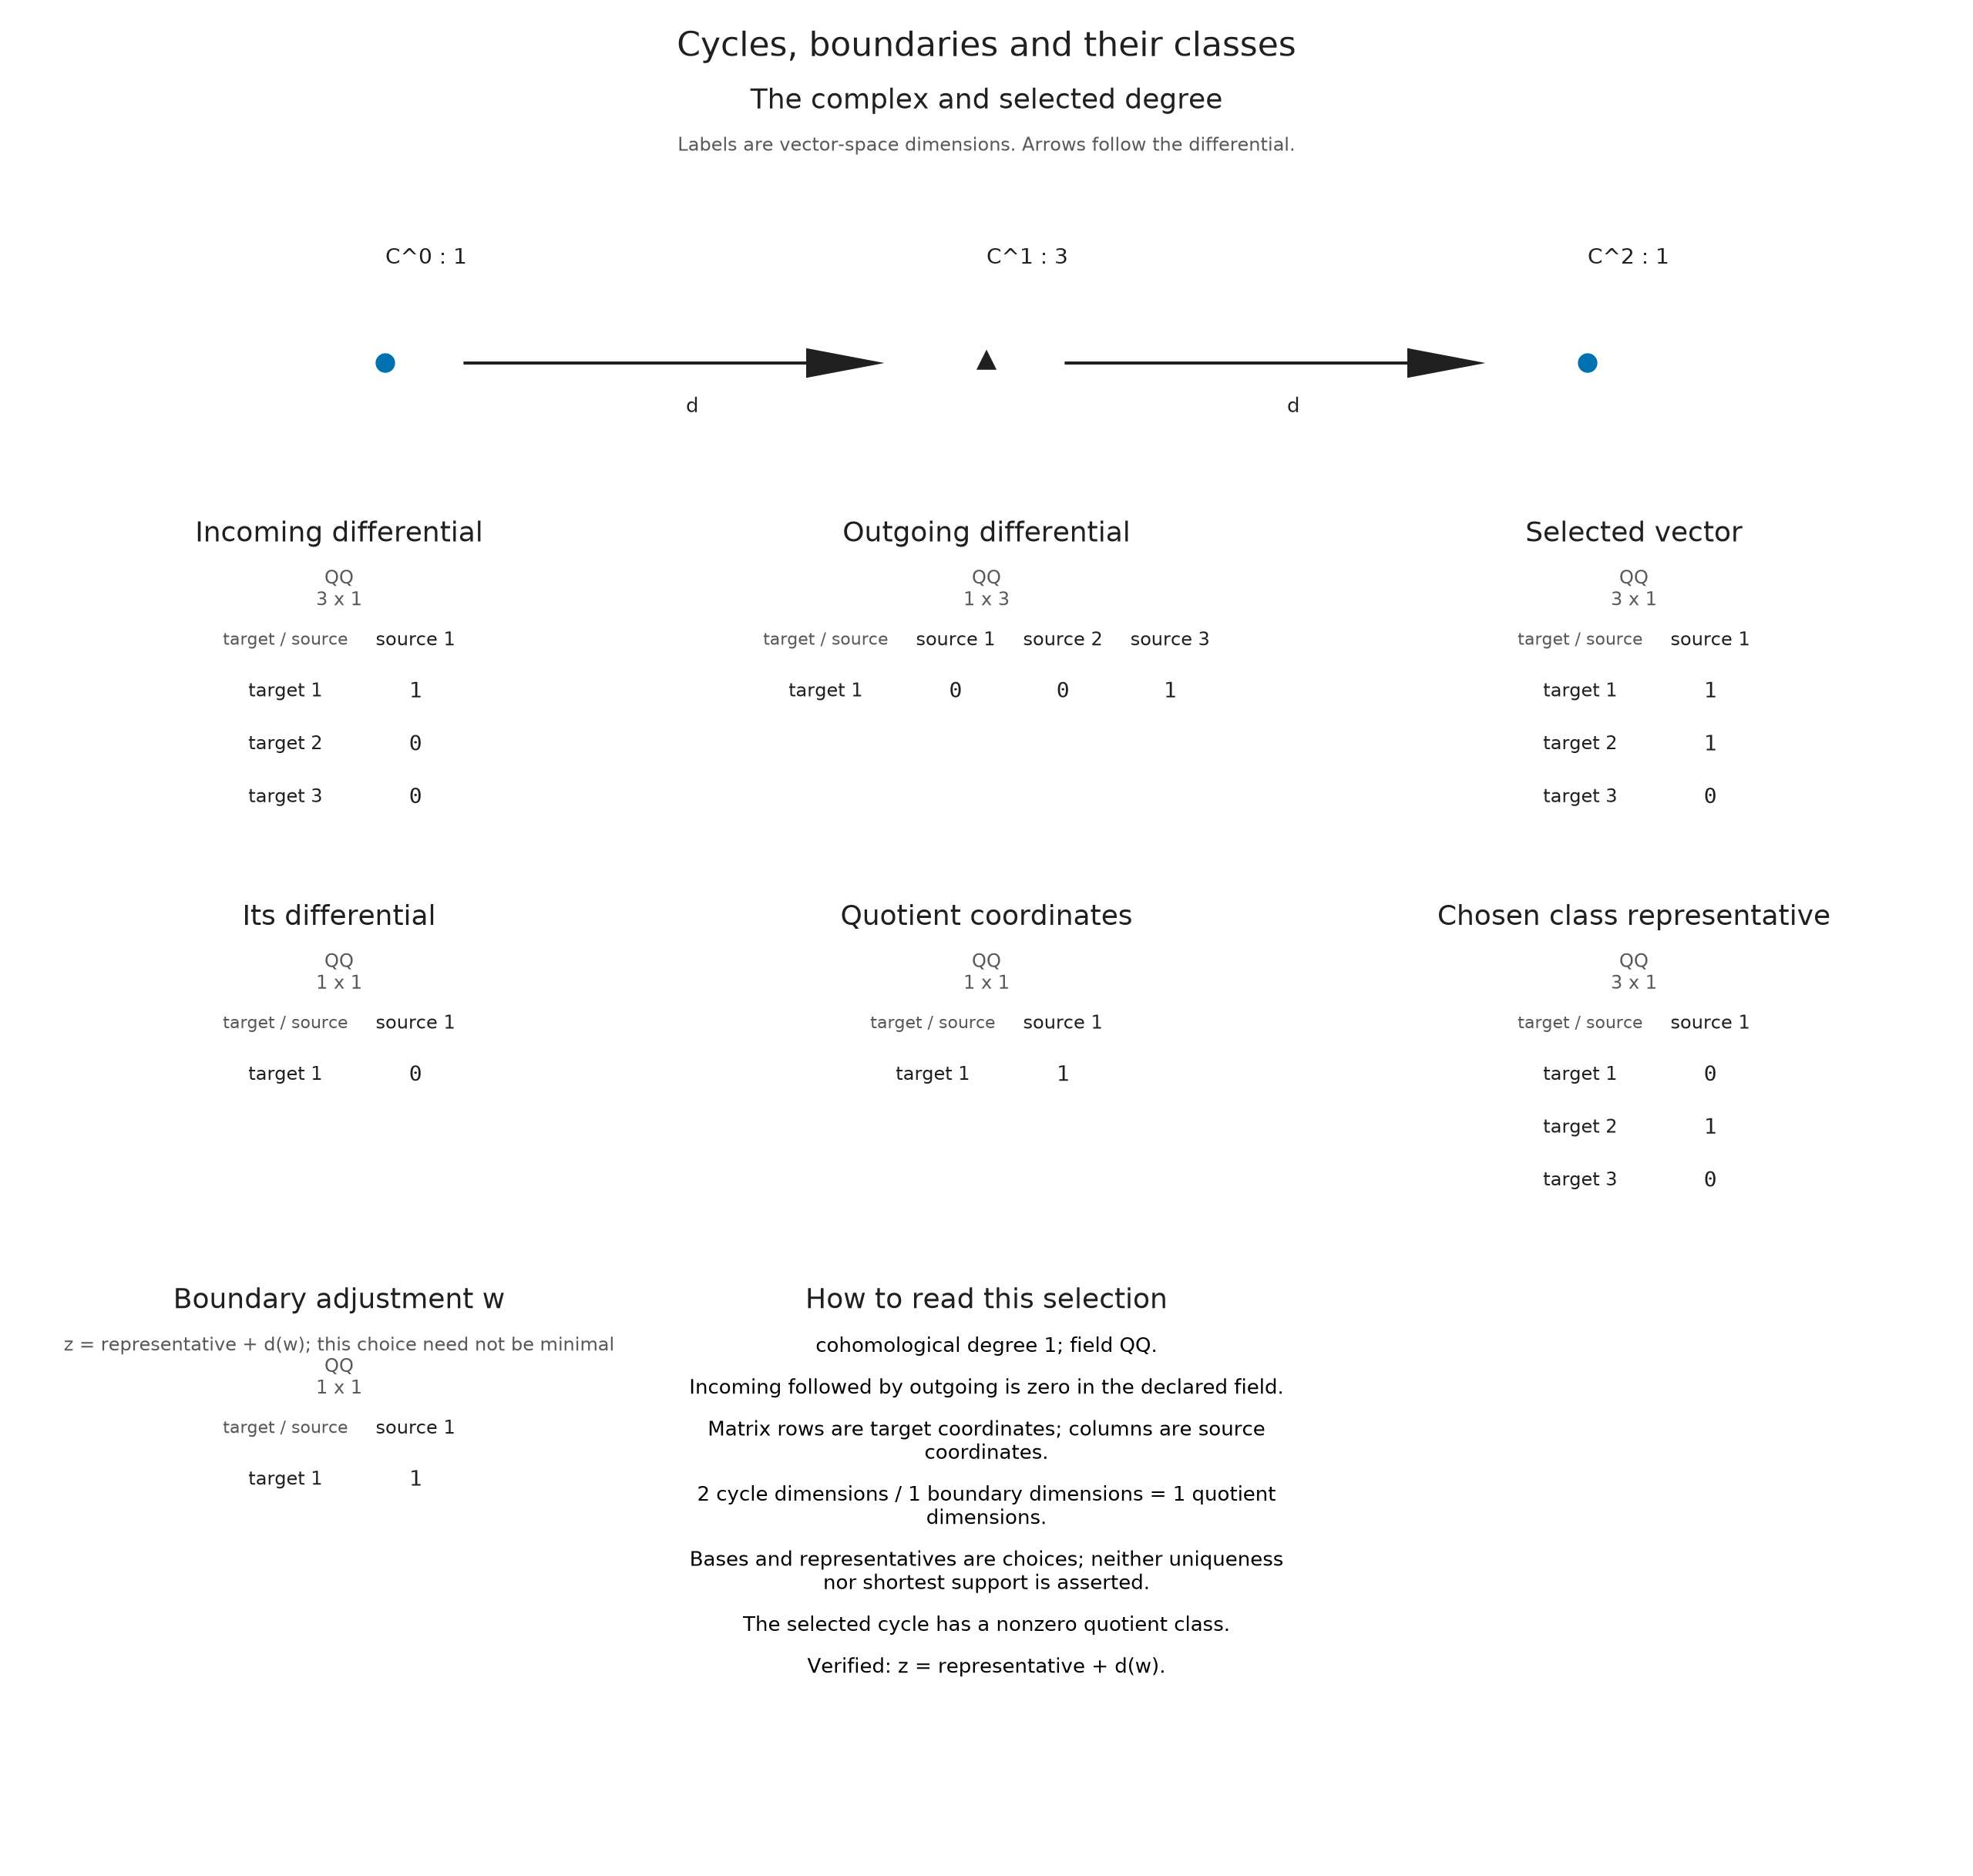

In [3]:
z = K[1,1,0]
selection = OA.visual_spec(C; degree=1, vector=z)
s = OA.visual_metadata(selection).selection
@assert s.is_cycle && !s.is_boundary
@assert z == s.representative + OA.differential(C,0) * s.boundary_adjustment
visualize(C; degree=1, vector=z)

The displayed representative is a coordinate choice. Its justification is the boundary equation; it carries no minimum-length or minimum-support claim.

Try $(1,0,0)$: it is a cycle, but its class is zero because it is an incoming boundary. Try $(0,0,1)$: its differential is nonzero, so it has no class in this quotient. For a zero-dimensional class space, an empty coordinate column denotes the zero vector in $K^0$.

Use `compute=true` when you also want the cycle, boundary and quotient bases. The `matrix_limit` option crops coefficient tables for display without changing the calculation.

## Follow a class through a map

Enlarge the incoming image to the whole cycle plane. The new complex $D$ has no degree-one cohomology. A map from $C$ to $D$ is the identity in degrees one and two; in degree zero it includes the original boundary generator as the first of the two new generators.

At the chain level, $z$ stays the same vector. At the quotient level, its image is zero. The target boundary adjustment explains why.

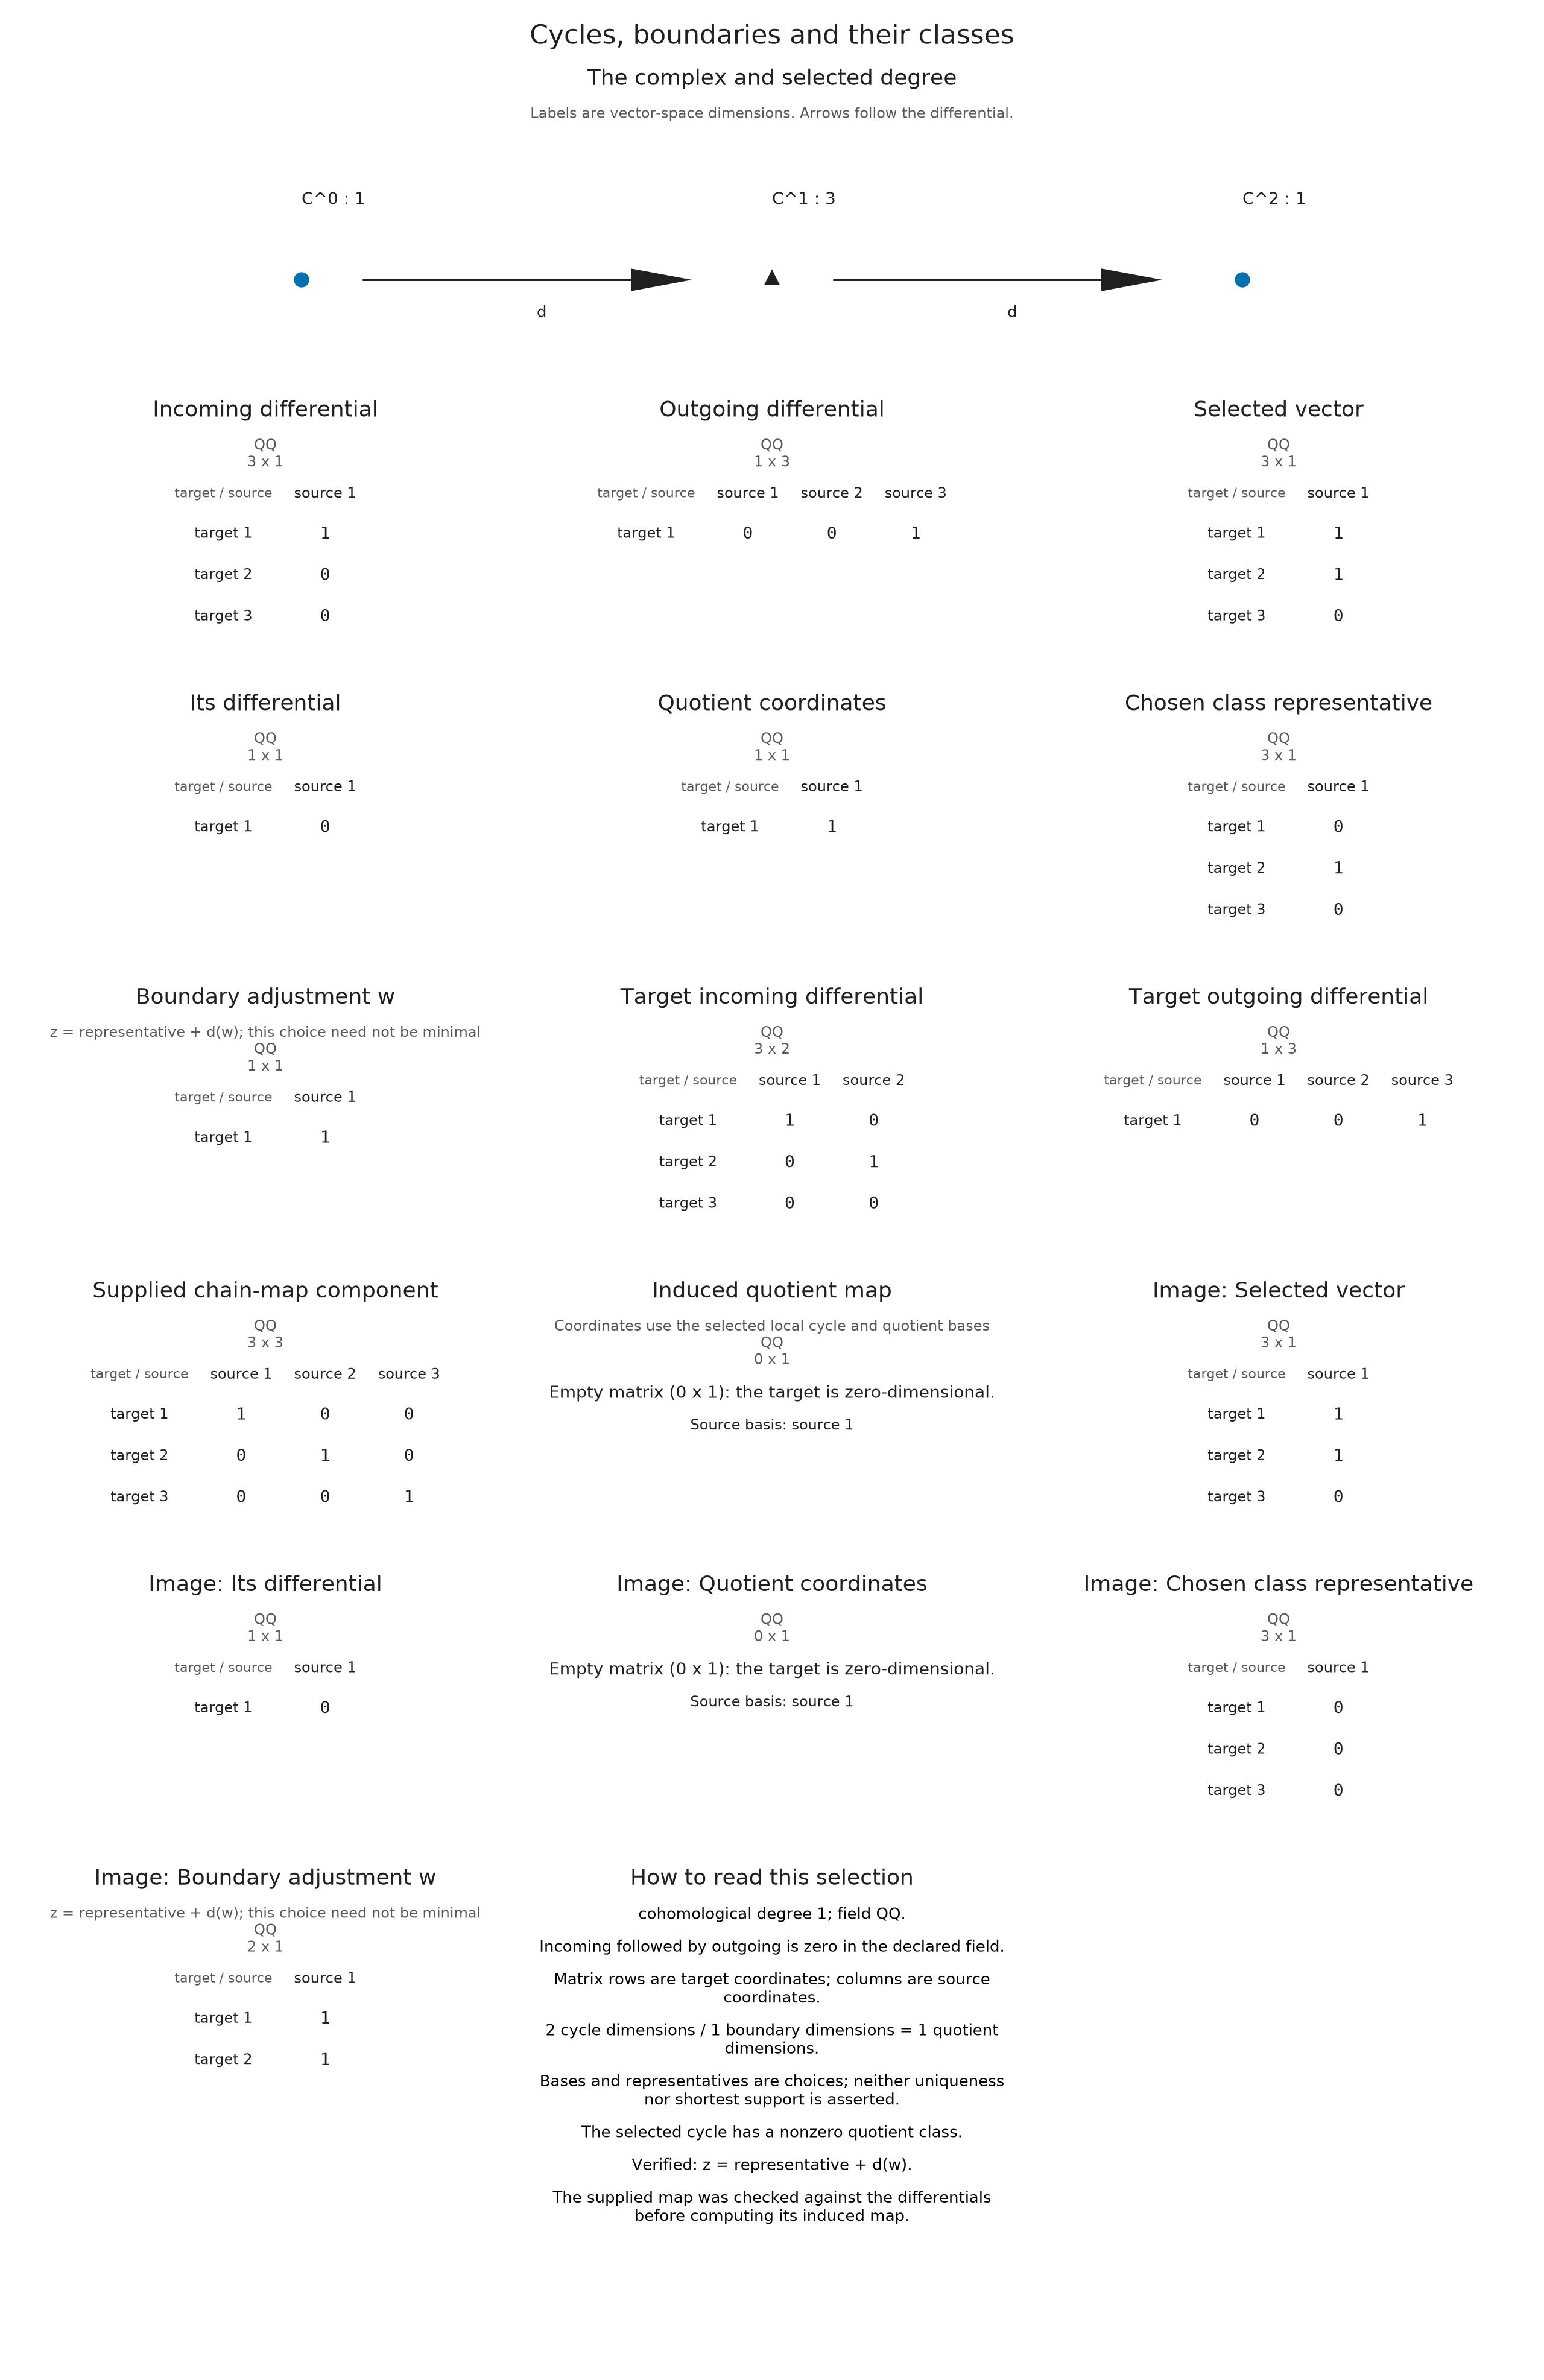

In [4]:
D = OA.CochainComplex{K}(0, 2, [2,3,1],
    [sparse(K[1 0; 0 1; 0 0]), sparse(reshape(K[0,0,1],1,3))]; field)
f = OA.CochainMap(C, D,
    [sparse(reshape(K[1,0],2,1)), sparse(K[1 0 0;0 1 0;0 0 1]), sparse(reshape(K[1],1,1))])
image_view = OA.visual_spec(f; degree=1, vector=z)
@assert OA.visual_metadata(image_view).map_data.target.selected.is_boundary
visualize(f; degree=1, vector=z)

For complexes of persistence modules, select a finite-poset `vertex`. The quotient bases displayed there are local to that stalk; they are not automatically the coordinates of a separately computed cohomology module. A supplied module cochain map accepts `kind=:chain_inspector`.

When a checked module cochain homotopy is available, `homotopy=H` displays its witness for $f-g=dh+hd$. Applied to a cycle, $h(z)$ explains why the two images represent the same class. The [chain inspection reference](../src/reference/visualization.md#chain-and-cochain-inspection) states the conventions.

For geometry, the [source-cell guide](source_cells.ipynb) retains actual oriented cells. `visualize(cells; kind=:chain_inspector, degree=1, parameter=...)` inspects the active chain complex, whose boundary lowers degree. Vector coordinates then index the active source cells listed by the view. A retained `SourceChain` brings its field, parameter and coefficients with it. No correspondence is inferred from a nearby point in a drawing.

## See a connecting map change degree

Take a one-dimensional complex $E$ concentrated in degree zero and its zero map to the zero complex. The cone is $E[1]$: its nonzero term is in degree $-1$. The connecting map sends $H^{-1}(\operatorname{Cone})$ to $H^0(E)$ and is the identity.

We request the full long exact sequence because this question needs maps and representatives. Its dimensions-only output is sufficient for counting, but does not retain the witnesses drawn here.

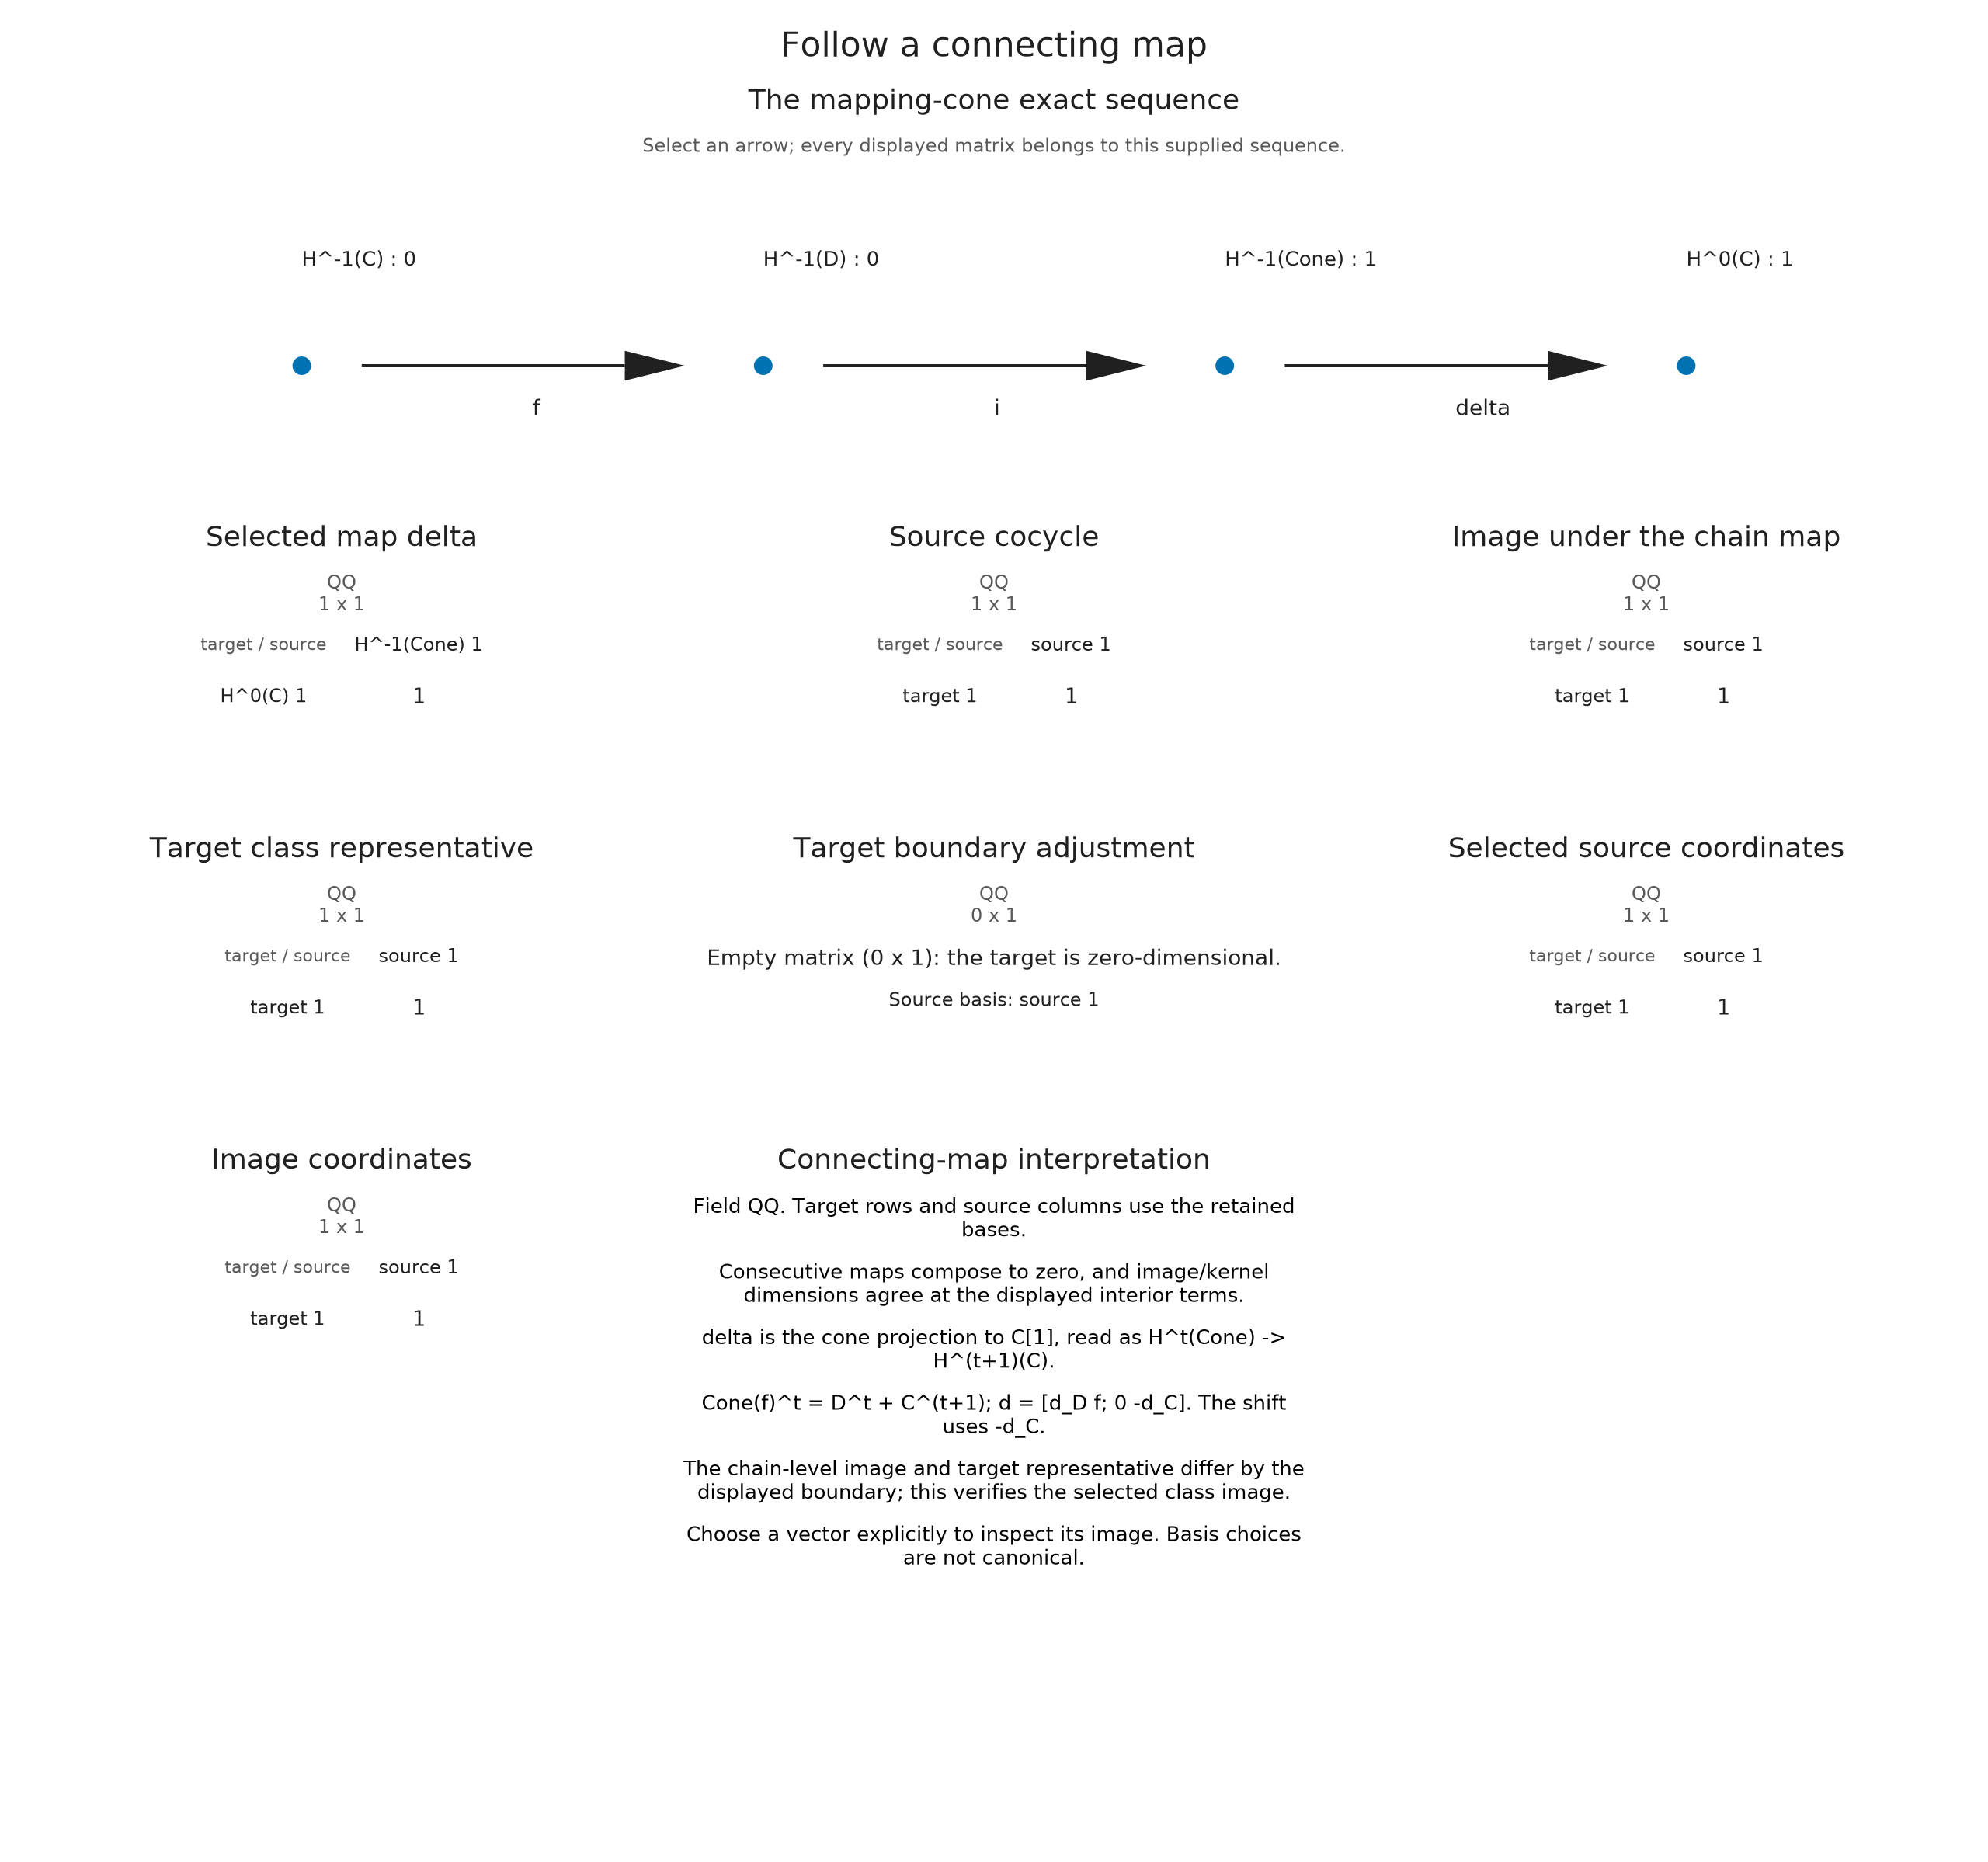

In [5]:
E = OA.CochainComplex{K}(0,0,[1],SparseMatrixCSC{K,Int}[]; field)
O = OA.CochainComplex{K}(0,0,[0],SparseMatrixCSC{K,Int}[]; field)
to_zero = OA.CochainMap(E,O,[spzeros(K,0,1)])
sequence = OA.long_exact_sequence(to_zero; output=:full)
connecting = OA.visual_spec(sequence; degree=-1, vector=K[1])
@assert OA.visual_metadata(connecting).selection.image_coordinates == K[1]
visualize(sequence; degree=-1, vector=K[1])

The convention is $\operatorname{Cone}(f)^t=D^t\oplus C^{t+1}$ with differential $\left[\begin{smallmatrix}d_D&f\\0&-d_C\end{smallmatrix}\right]$. Its projection to $C[1]$ produces the connecting map. The minus sign belongs to the shifted differential and matters over fields of odd characteristic.

A computed snake-lemma result has a related view: select one of its five maps at a finite vertex. That result retains the kernel/cokernel sequence, so the viewer uses those coordinates without inventing the original two-row diagram or missing chase lifts.

### Explore a vector interactively

With WGLMakie and a running Julia session:

```julia
using WGLMakie
chains = inspection_session(C; degree=1)
visualize(chains; backend=:wglmakie)
```

Click a degree, enter a vector, or switch to quotient coordinates. Selecting a new degree clears the old vector because it belonged to the previous space. Invalid input leaves the previous view intact. For a connecting-map session, click an arrow and enter coordinates in its source space.

The same choices are available through `OA.select_inspection!` and `OA.inspection_snapshot`; a snapshot can be saved as a static figure. Hover only reads prepared dimensions. Close the session with `OA.close_inspection!` when finished.

## Add a filtration to organize the calculation

A filtration lets a larger calculation be studied through successive approximations. The next example has a zero first-page differential and a nonzero second-page differential. We will compare those pages with the associated graded total cohomology.

## Describe the filtered pieces

The constructor uses `(p,t)`: filtration index and total cohomological degree.
The chart will use `(p,q)`, with `q=t-p`. Each of these four pieces is `K²`:

```text
(p,q) = (0,1) --I--> (1,1)
                       ^ I
                       |
                    (1,0) --T--> (2,0)
```

Here `I` is the identity and `T=diag(1,0)`. The vertical map preserves filtration;
the horizontal maps raise it by one. Omitted pieces and maps are zero. This
constructor describes a split bicomplex, with the constructor's total-differential sign
convention; it is not an arbitrary filtered complex with unspecified higher
filtration-jump components.

In [6]:
I2 = sparse(K[1 0; 0 1])
T = sparse(K[1 0; 0 0])
pieces = Dict((0,1)=>2, (1,1)=>2, (1,2)=>2, (2,2)=>2)
dc = OA.filtered_cochain_complex(K; field, pieces,
    d0=Dict((1,1)=>I2),
    d1=Dict((0,1)=>I2, (1,1)=>T))
OA.check_bicomplex(dc; throw=true)

(kind = :bicomplex, valid = true, a_range = (0, 2), b_range = (-1, 2), total_degree_range = (-1, 4), issues = String[])

The first page takes vertical cohomology. The middle identity cancels its two
pieces, leaving `K²` at `(0,1)` and `(2,0)`. A first differential moves by `(1,0)`,
so neither surviving term has a nonzero first-differential target. Both therefore
remain on the second page. Predict its two dimensions before drawing it.

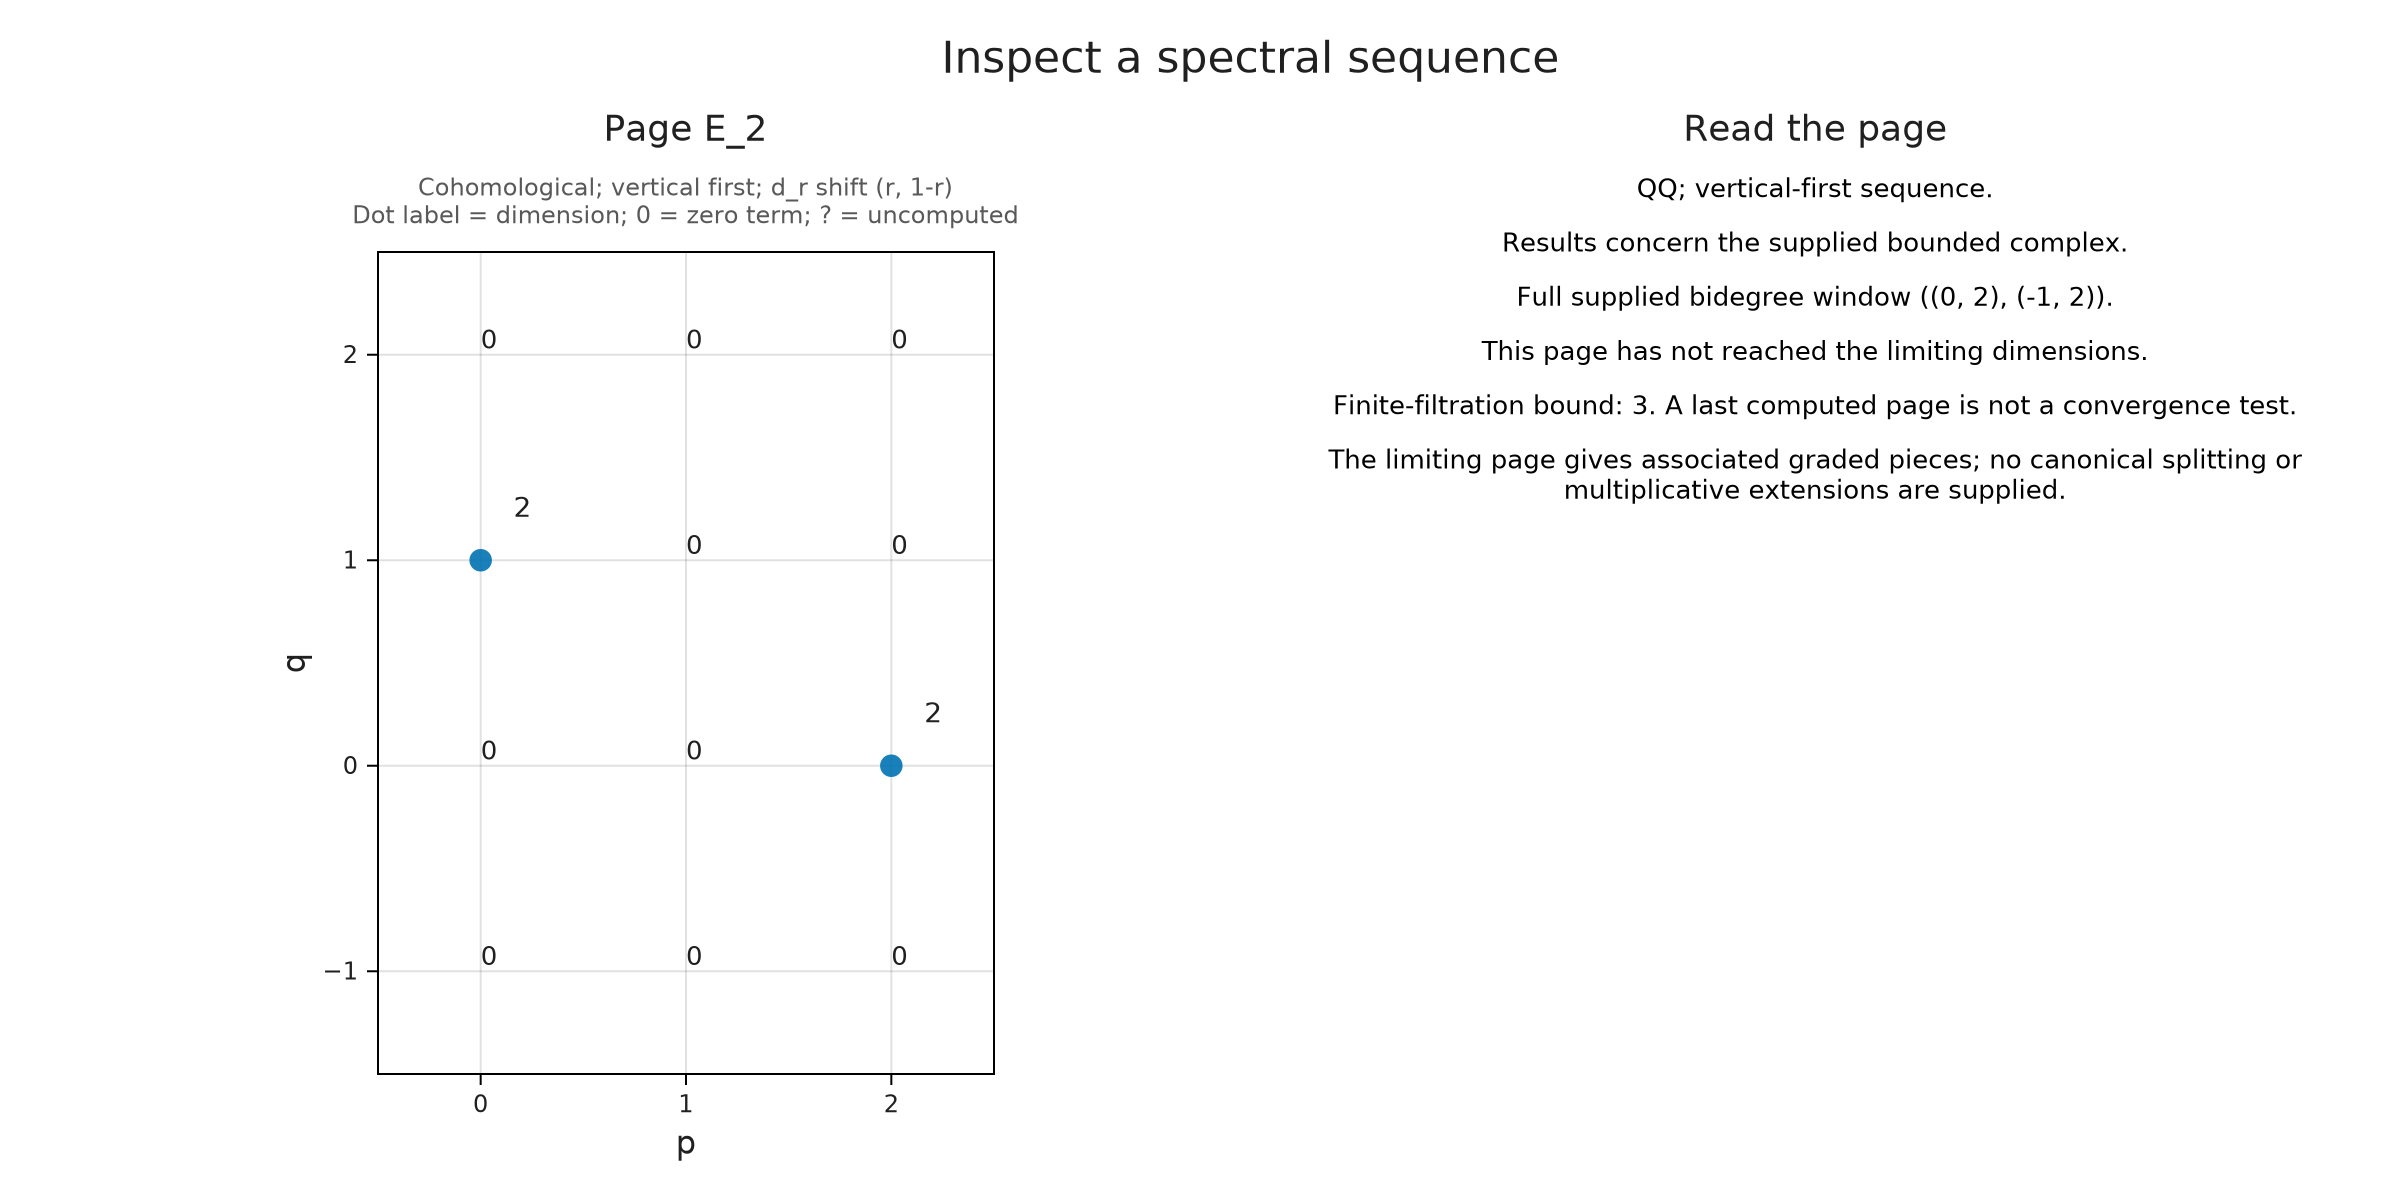

In [7]:
ss = OA.spectral_sequence(dc; output=:full)
@assert OA.term_dims(ss; page=2) == Dict((0,1)=>2, (2,0)=>2)
visualize(ss)

A dot represents a whole term, and its label is its dimension. The coordinates
are spectral bidegrees, not geometric positions in the original parameter
space. Zero terms are printed as `0`; an uncomputed page would display `?`.

## Inspect the map that changes the answer

A second differential moves by `(2,-1)`. Starting at `(0,1)`, the first horizontal
identity can be lifted through the middle vertical identity. The remaining
horizontal map is `T`. With this totalization convention, the result is therefore
`d₂=T`, of rank one.

Select its **source bidegree**. The matrix uses target rows and source columns,
and the other panels describe its kernel and image in the chosen page bases.

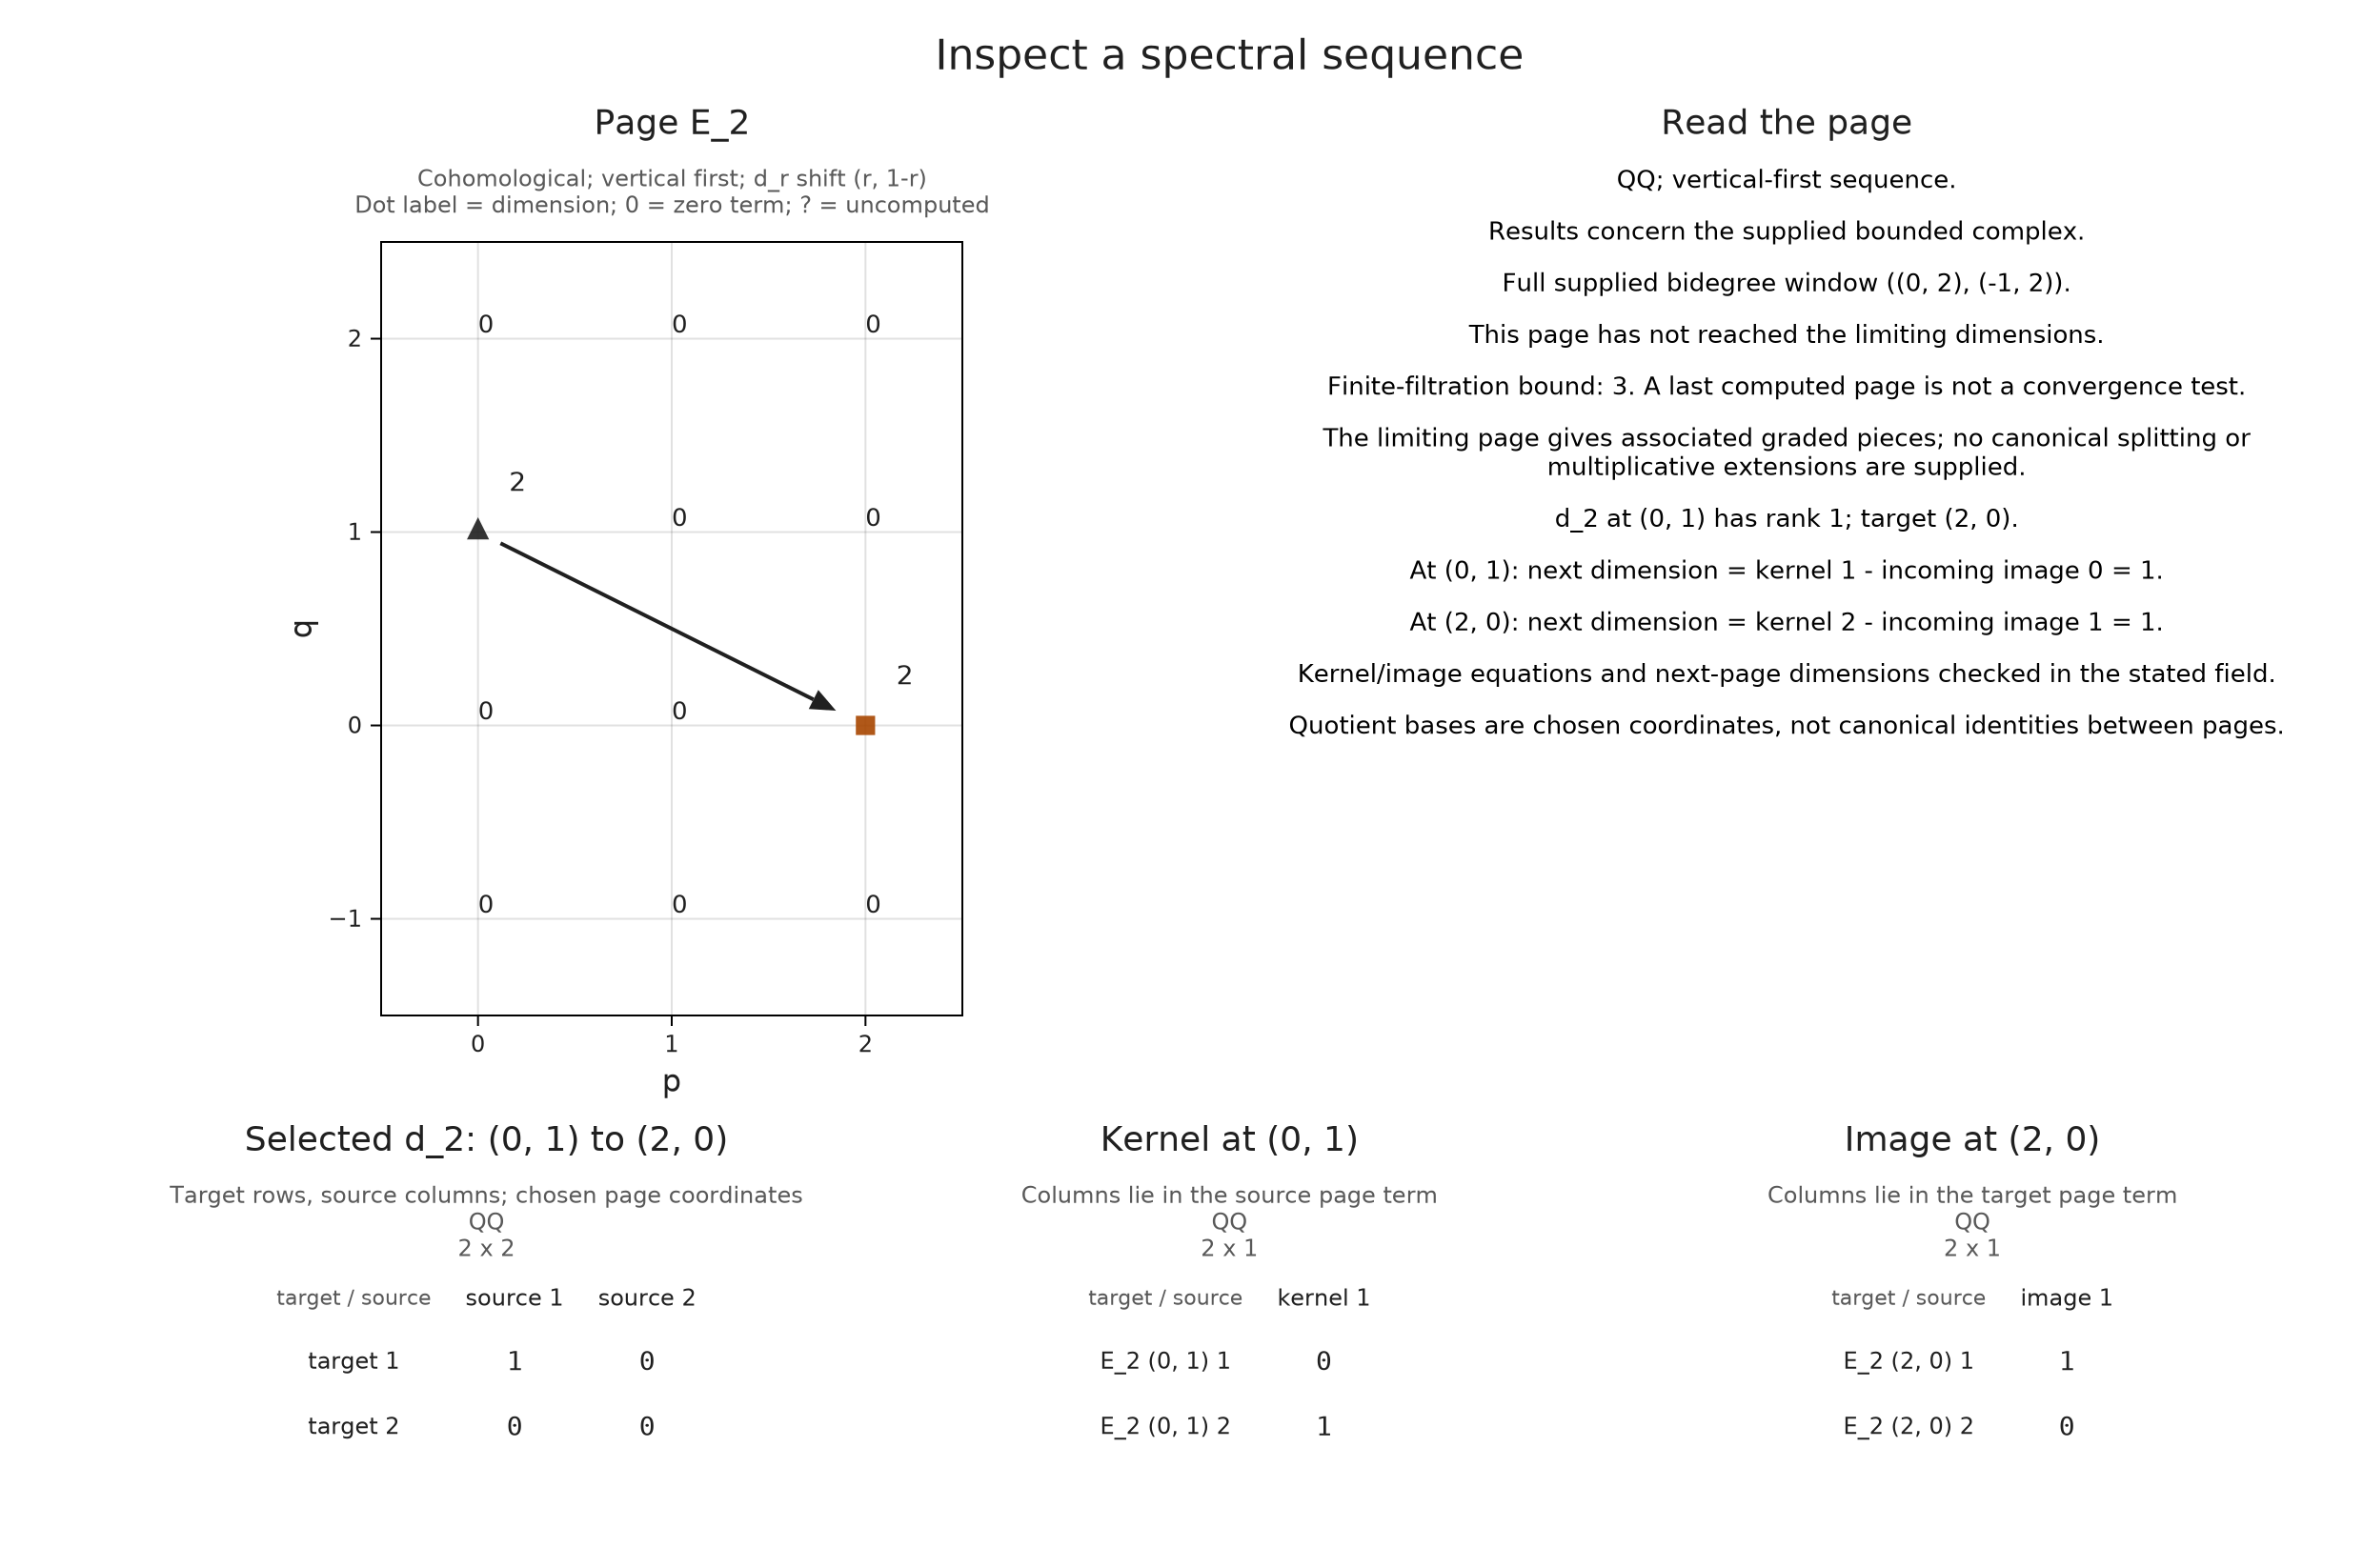

In [8]:
d2 = OA.differential(ss; page=2, p=0, q=1)
@assert Matrix(d2) == Matrix(T)
visualize(ss; kind=:spectral_differential, source=(0,1))

At the source, the next term is `ker(d₂)/im(d₂ incoming)`: one dimension survives
because there is no incoming image. At the target, the outgoing map is zero,
but the incoming image removes one of the two dimensions. Both terms on the
third page should have dimension one.

The readout checks these quotient dimensions against the computed next
page. Its kernel and image bases are coordinates in the current page, not
canonical identifications of individual vectors across all pages.

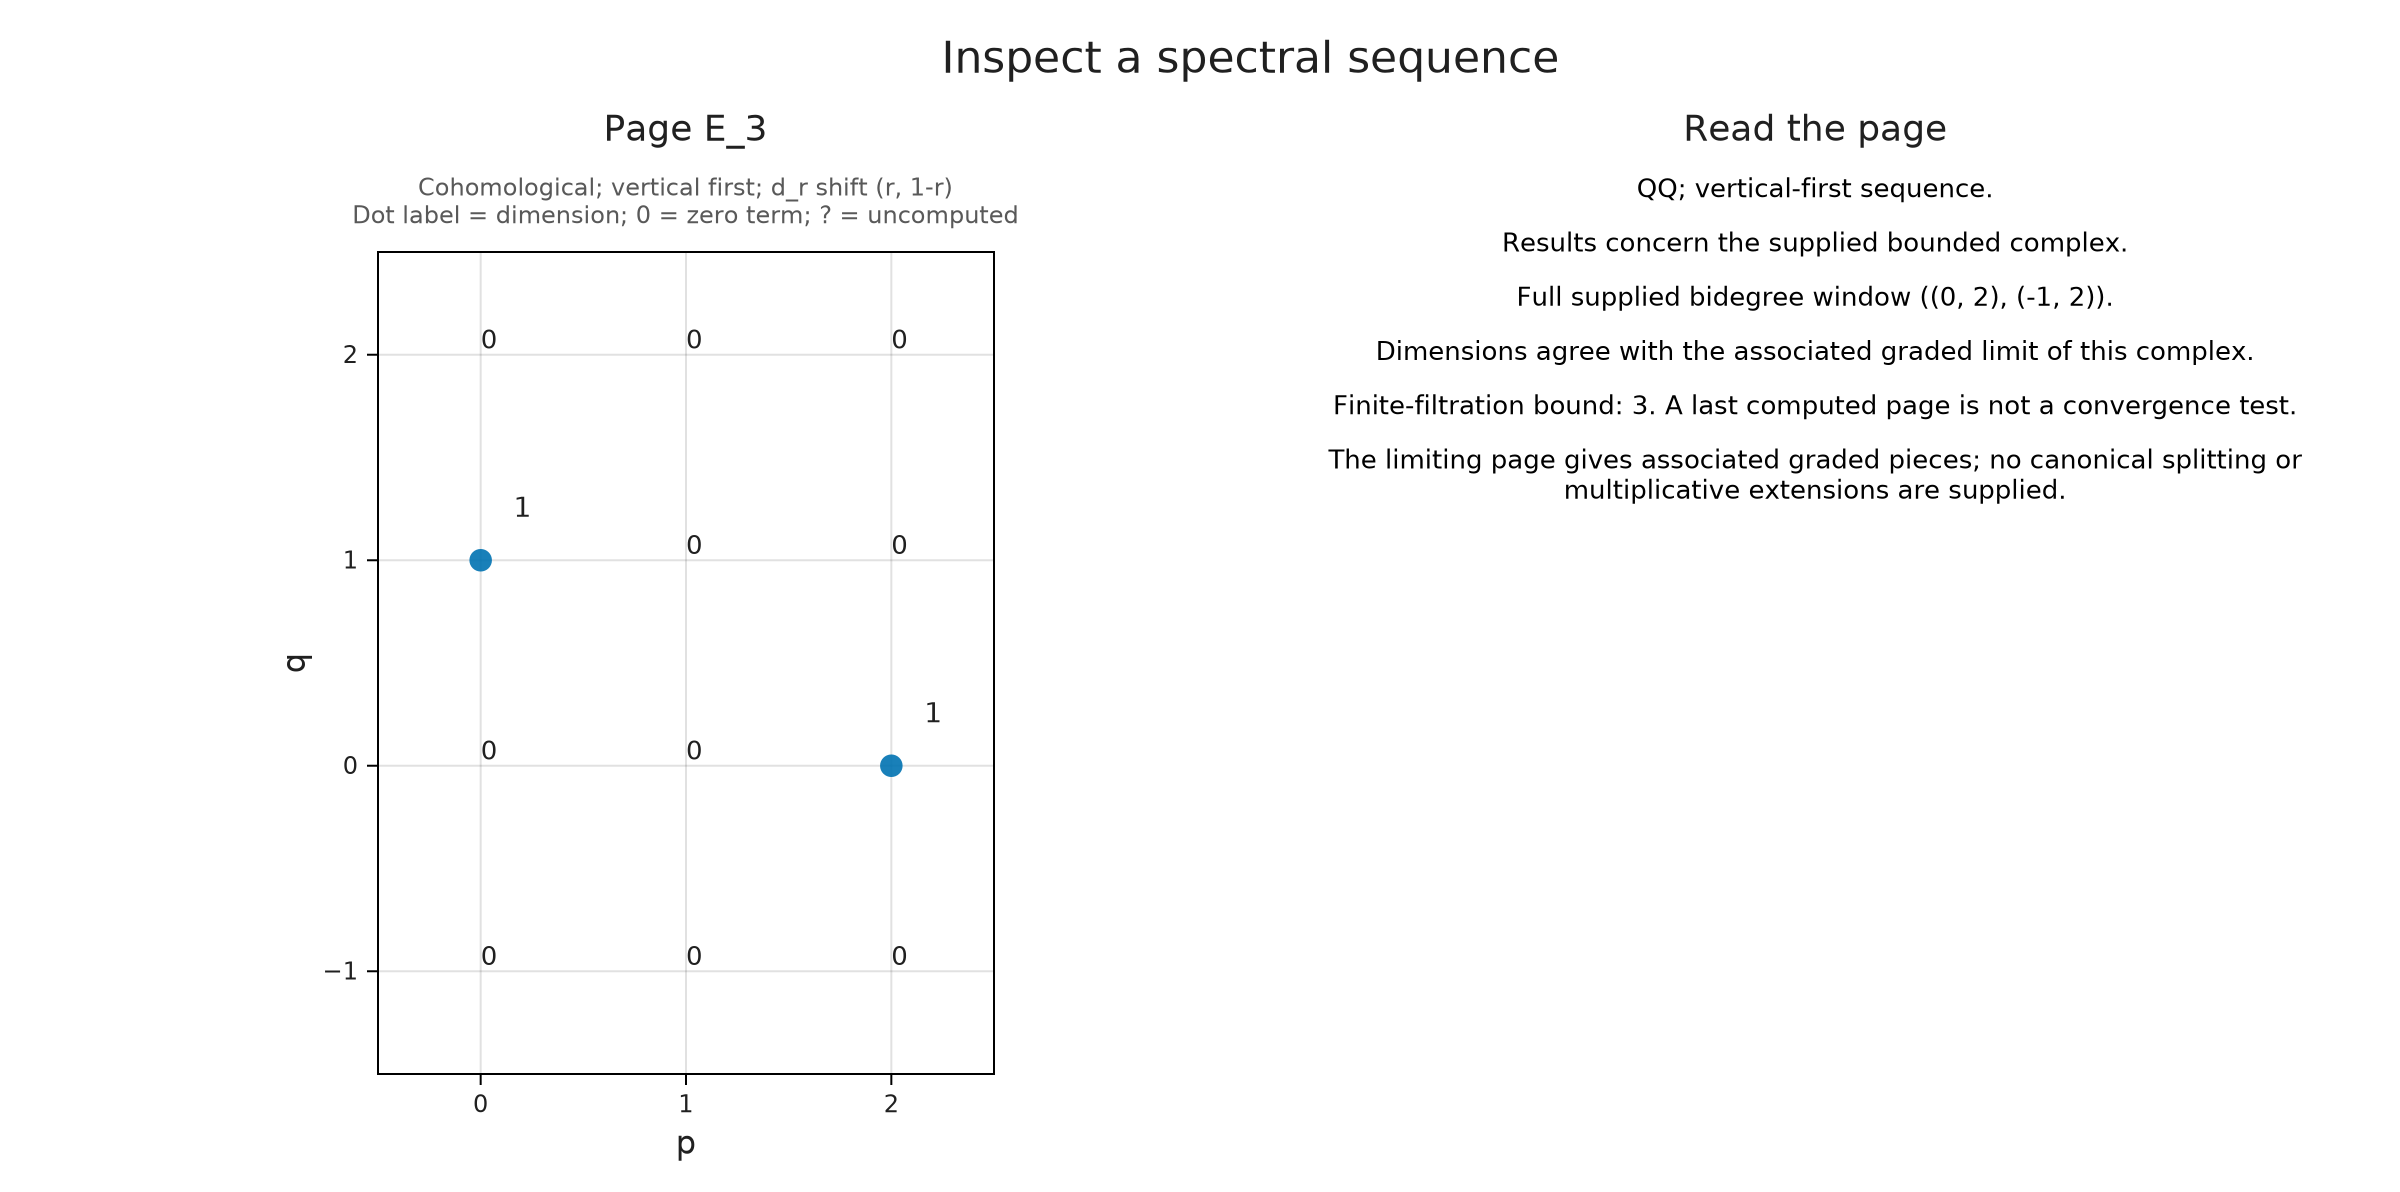

In [9]:
@assert OA.term_dims(ss; page=3) == Dict((0,1)=>1, (2,0)=>1)
visualize(ss; page=3)

## Read the limit without inventing a splitting

For this bounded complex, these dimensions agree with the independently
computed associated graded total cohomology. Requesting the limiting page uses
that object; it does not merely rename the highest page in a cache.

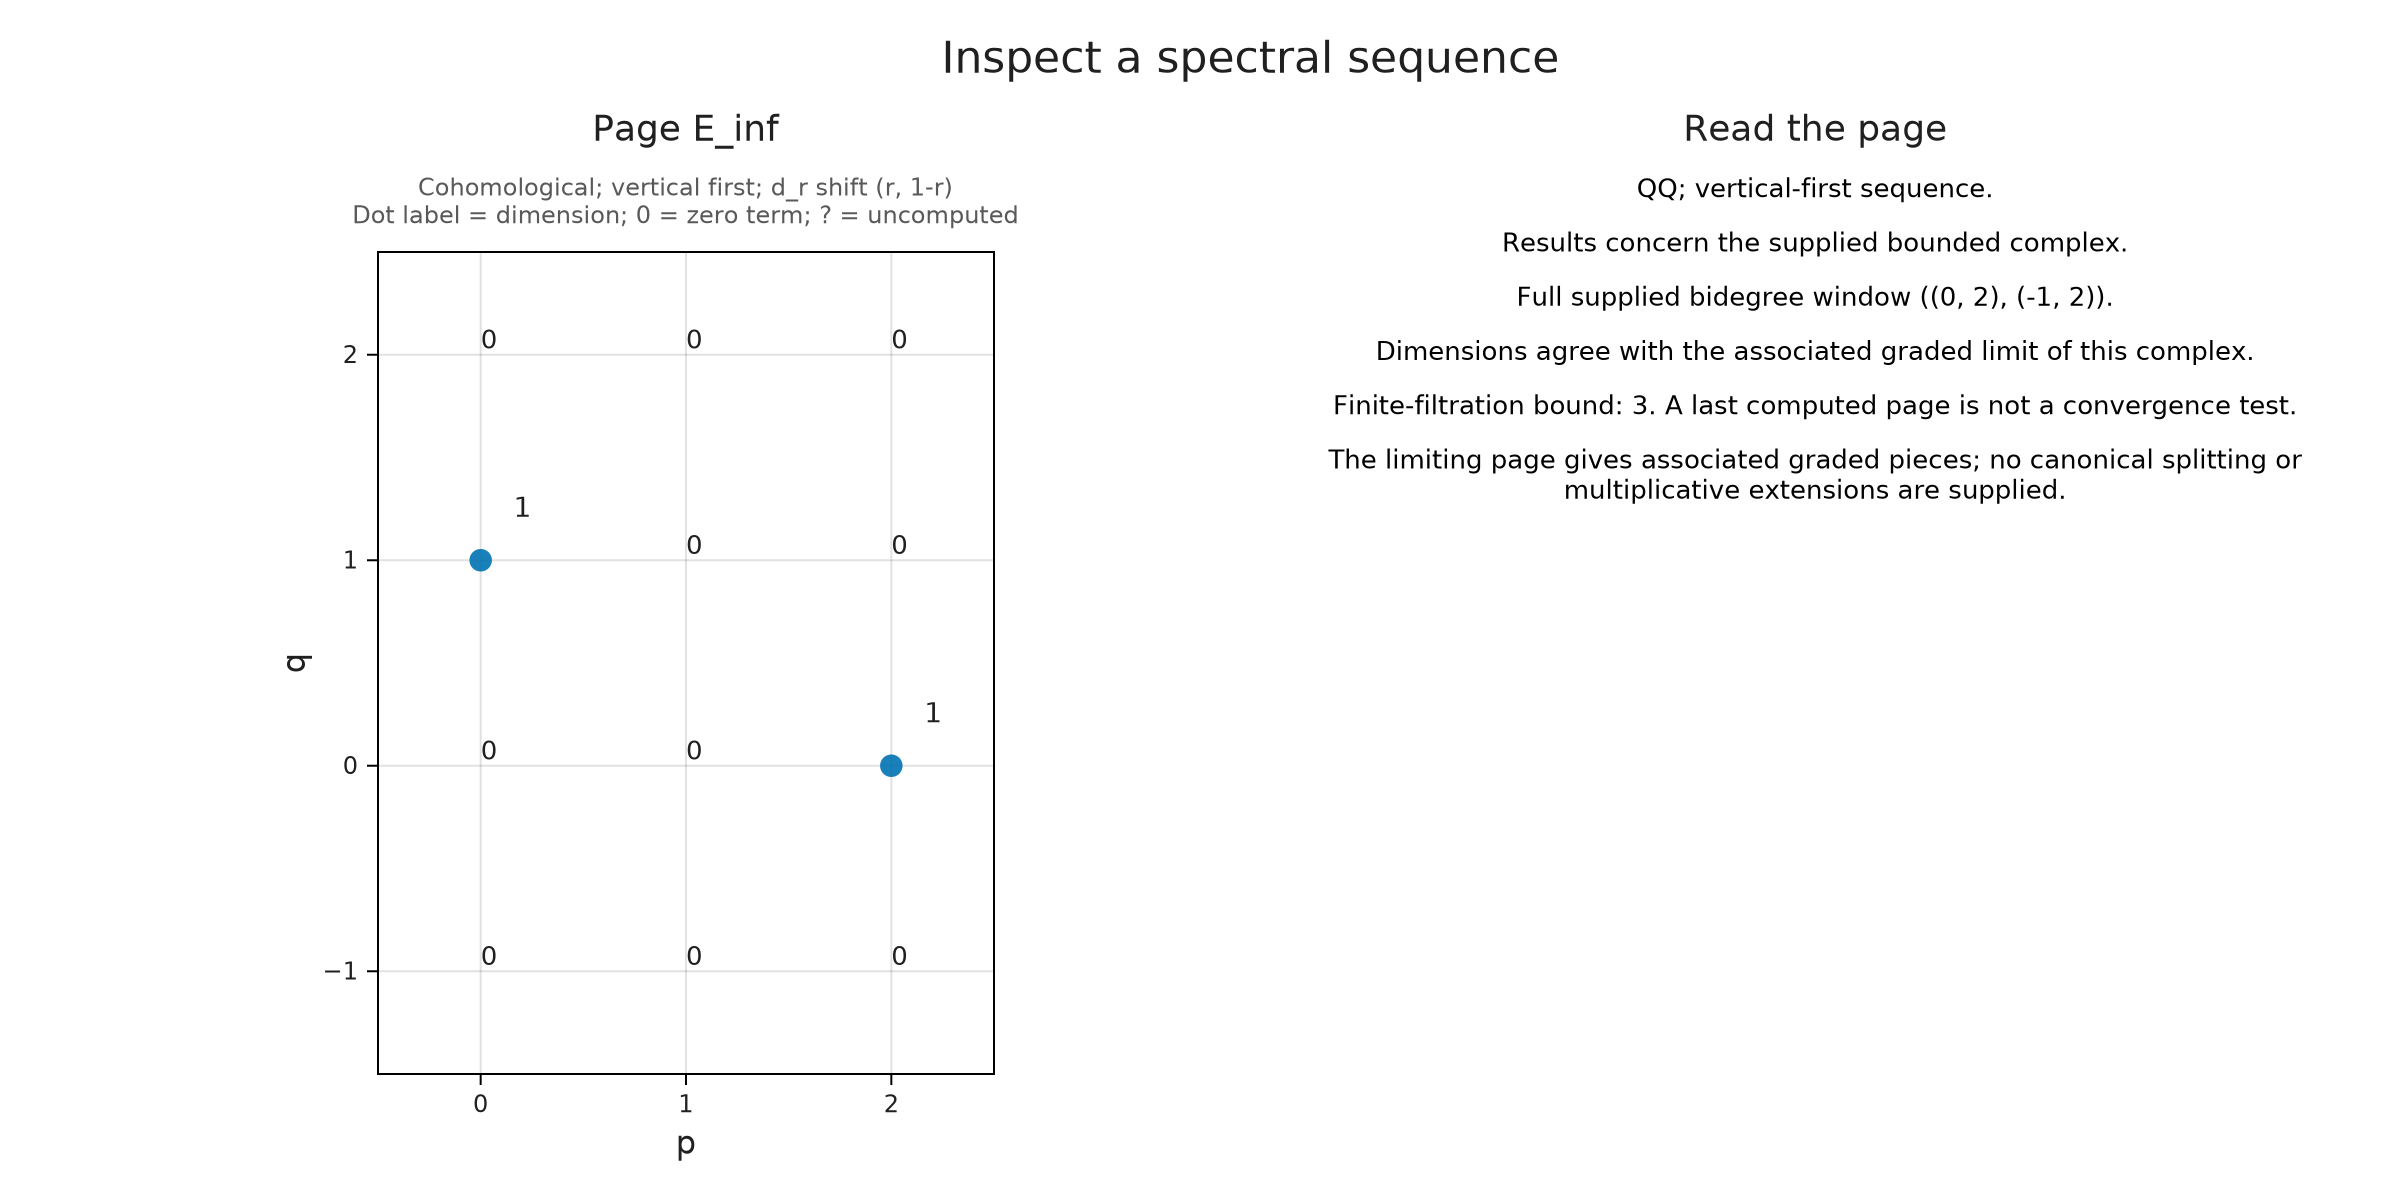

In [10]:
visualize(ss; page=:inf)

The surviving pieces contribute to total degrees `p+q=1` and `2`. More generally,
several pieces can belong to the same total degree. Over a field their dimensions
add, but the chart does not choose a canonical splitting or reconstruct
multiplicative extensions.

A supplied complex may itself be a truncation of a larger intended computation.
Use `truncated=true` to keep that scope visible. A `window` instead crops only
the drawing: it does not remove terms or change the algebra.

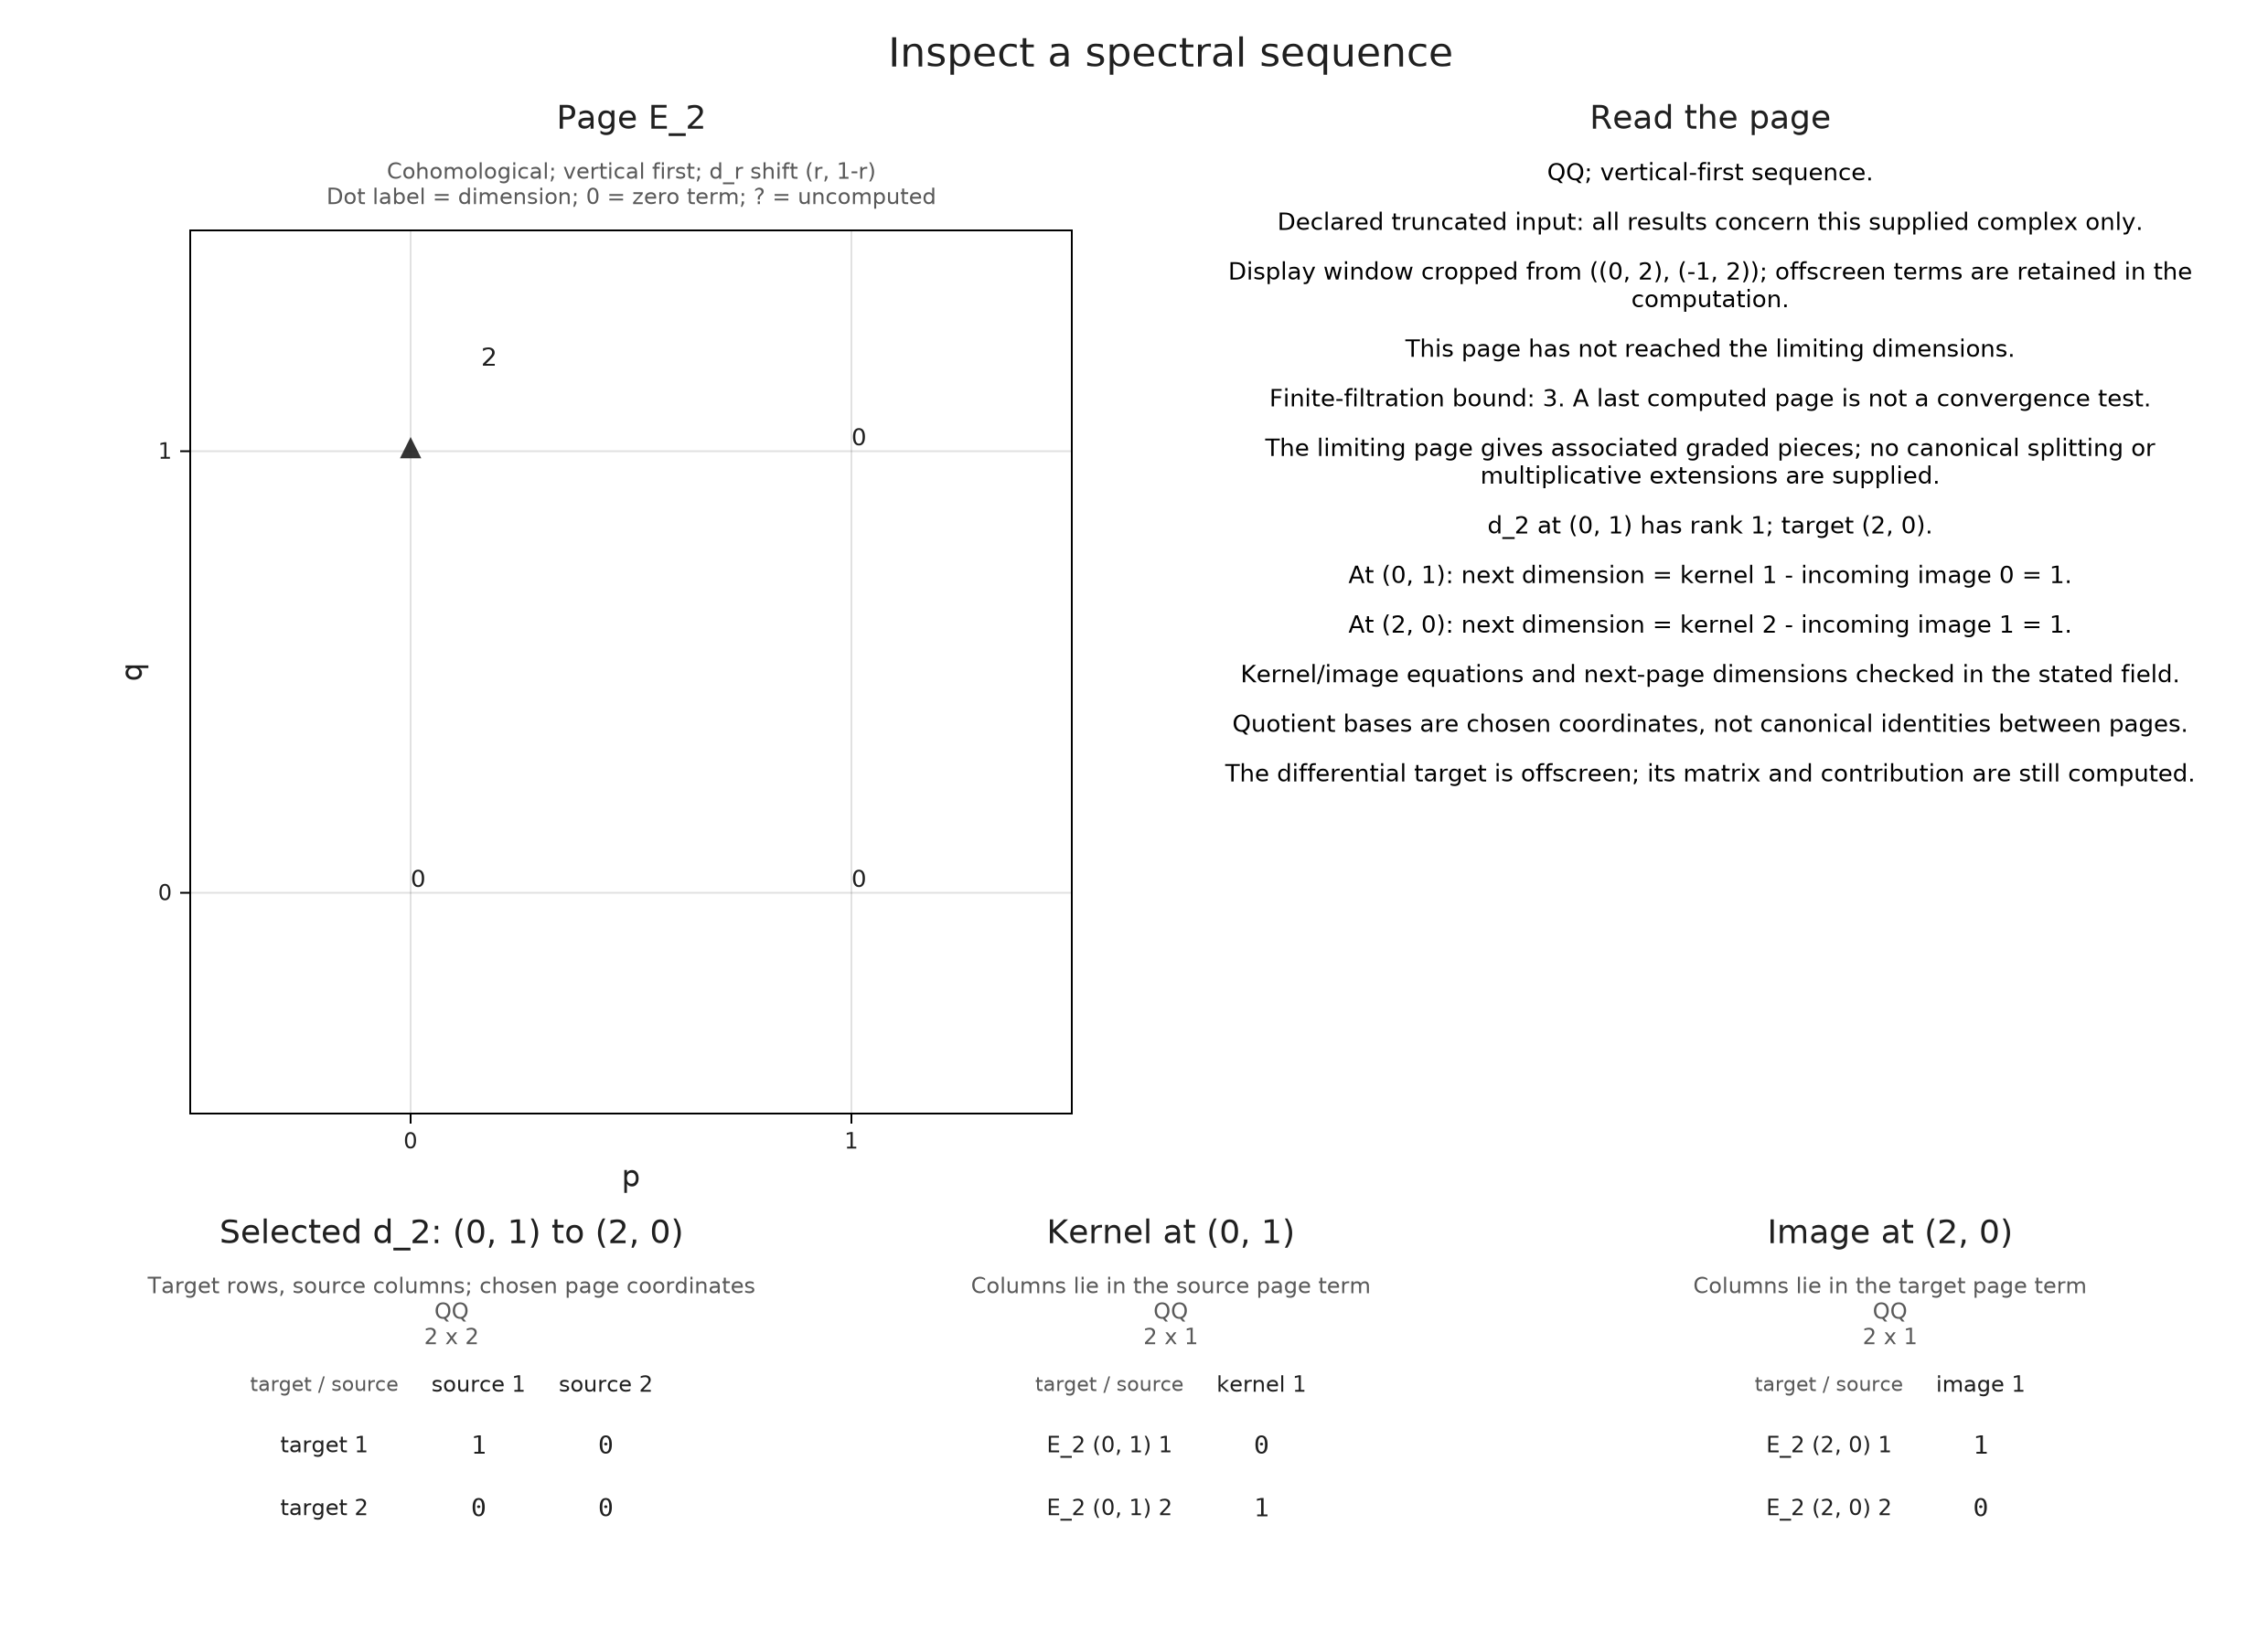

In [11]:
visualize(ss; kind=:spectral_differential, source=(0,1),
    window=((0,1),(0,1)), truncated=true)

## Explore pages with a live Julia session

The same objects support linked browser controls. This optional code requires
WGLMakie and a running Julia session:

```julia
using WGLMakie
session = inspection_session(ss)
visualize(session; backend=:wglmakie)
```

Change the page, click a term to inspect its outgoing differential, or enter its
bidegree. Disable **Compute requested missing data** to inspect only retained
pages and maps. Missing data then stays unknown; hovering never computes it.
The associated graded button states the supplied-complex scope. Invalid entries
leave the previous selection intact.

The same choices are available without a browser:

```julia
OA.select_inspection!(session; page=2, source=(0,1))
OA.select_inspection!(session; page=3)
OA.inspection_snapshot(session)
OA.close_inspection!(session)
```

A snapshot is a static exportable figure. Closing releases the live inputs and
callbacks while preserving that final snapshot.

## Other conventions and supplied structure

Horizontal-first computations use `dᵣ:(p,q)→(p-r+1,q+r)`; vertical-first ones use
`(p+r,q-r+1)`. A Tor spectral sequence reverses both bidegrees and lowers total
homological degree. The viewer reads the convention from the supplied object.
Do not transpose a chart manually and keep its old arrow labels.

If an independent computation supplies a linear map between two terms, the
`structure_maps` option can draw a labelled dashed line from its actual matrix.
The viewer checks dimensions and coefficients. Calling that line multiplication
by a class does not itself verify a product law or a Leibniz identity. See the
[method reference](../src/reference/visualization.md#spectral-pages-and-differentials)
for the contract.

Try replacing `T` by the zero matrix and constructing a fresh sequence. What
changes? The second differential now vanishes, so both two-dimensional terms
survive. Compare that result with replacing `T` by the identity, when both terms
disappear. Rebuild the sequence after changing the input; do not mutate data
behind an already computed page cache.

For the resolution data that can feed such calculations, continue with
[Working with resolutions](resolutions.ipynb). The
[visualization guide](../visualization.md) covers shared styling and exports.